<a href="https://colab.research.google.com/github/ricardoasf/Previsao-Series-Temporais/blob/main/MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
#Definição das bibliotecas usadas
import pandas as pd #álgebra linear
import numpy as np #processamento de dados

import matplotlib as mpl
import matplotlib.pyplot as plt #visualização de dados
import seaborn as sns #visualização de dados

############### PARAMETRIZAÇÃO PARA EXECUÇÃO #############
# 1 - para Jupyter/Outras IDEs;
# 2 - para GoogleColab
carga_dados = 2
##########################################################

if carga_dados == 1:
    #Carrega Série Temporal a partir de Planilha de Dados no formato de DataFrame
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk()
    root.withdraw()
    caminho_arquivo = filedialog.askopenfilename()
    df = pd.read_csv(caminho_arquivo)
else:
    #Carrega Dados para GoogleColab
    import io
    from google.colab import files
    uploaded = files.upload()
    #Obtém o nome do arquivo que foi feito upload
    nome_arquivo = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[nome_arquivo]))

df

Saving Dataset2.csv to Dataset2 (1).csv


,Data,Demanda,Dolar,Eolica,Balanco,Preco
0,7/1/2009 0:00,12336,1.1572,37,-1310,14.25
1,7/1/2009 1:00,11973,1.1572,13,-1561,8.43
2,7/1/2009 2:00,11731,1.1572,15,-1890,1.88
3,7/1/2009 3:00,11553,1.1572,20,-1764,11.00
4,7/1/2009 4:00,11588,1.1572,26,-1962,4.21
...,...,...,...,...,...,...
1003,8/11/2009 19:00,19179,1.0843,131,-1117,33.12
1004,8/11/2009 20:00,19192,1.0843,83,-898,38.14
1005,8/11/2009 21:00,17504,1.0843,74,-1080,34.04
1006,8/11/2009 22:00,15912,1.0843,67,-995,20.80


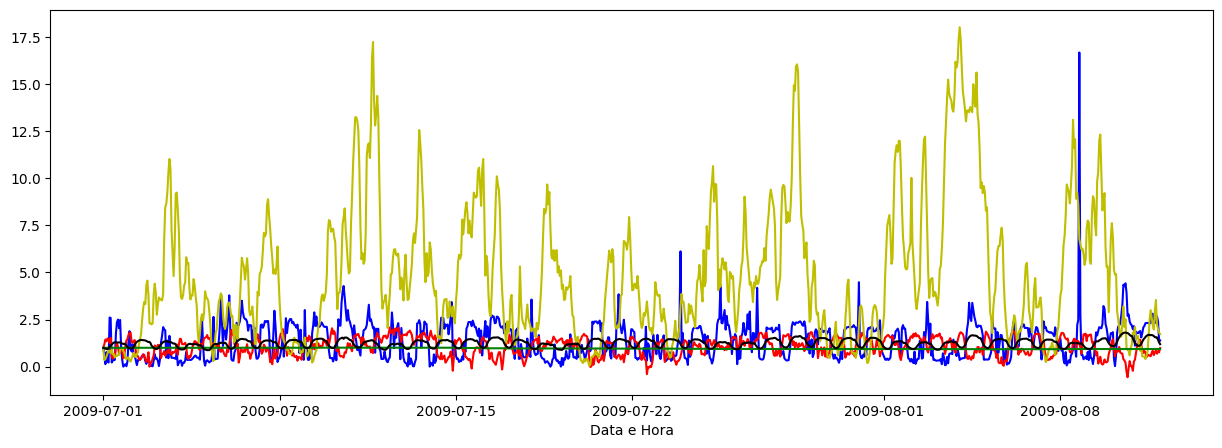

In [14]:
#Transforma a Coluna Data em DateTime
df['DateTime'] = pd.to_datetime(df['Data'])

#Torna a Coluna DateTime o índice do DataFrame
df = df.set_index(df['DateTime'])

#Clona o DataFrame e Normaliza as Colunas pela primeira amostra
df_clone = df[:]
df_clone['Demanda'] = df['Demanda'] / df['Demanda'].iloc[0]
df_clone['Dolar'] = df['Dolar'] / df['Dolar'].iloc[0]
df_clone['Eolica'] = df['Eolica'] / df['Eolica'].iloc[0]
df_clone['Balanco'] = df['Balanco'] / df['Balanco'].iloc[0]
df_clone['Preco'] = df['Preco'] / df['Preco'].iloc[0]

#Copia apenas as colunas de interesse do Clone para o novo DataFrame
df_norm = df_clone[['Demanda','Dolar', 'Eolica', 'Balanco', 'Preco']]
df_norm

#Análise Gráfica dos Dados
plt.figure(figsize=(15,5))
plt.plot(df_norm['Preco'], 'b')
plt.plot(df_norm['Balanco'], 'r')
plt.plot(df_norm['Eolica'], 'y')
plt.plot(df_norm['Dolar'], 'g')
plt.plot(df_norm['Demanda'], 'k')
plt.xlabel('Data e Hora')
plt.show()

In [15]:
#Detecção/Remoção das Linhas com Valores Faltantes
df_missing = pd.isnull(df_norm['Preco'])
if (df_norm[df_missing].size > 0):
    df_cleaned = df_norm.dropna()
else:
    df_cleaned = df_norm

#Remoção de Outliers
df_cleaned = df_cleaned[df_cleaned['Preco'] <= 5]

#Clona o DataFrame normalizado para um novo
df_lagged = df_cleaned[:]

#Determina os atrasos (em amostras)
lags = (1, 2, 3, 4, 5)

#Gera o DataFrame com as Colunas de Atraso
df_lagged = df_cleaned.assign(**{f'{col}_t-{lag}': df_cleaned[col].shift(lag) for lag in lags for col in df_cleaned})

#Calcula Média Móvel Simples
tamanho_janela = 5 #em amostras
janelas = df_cleaned['Preco'].rolling(tamanho_janela)
MA = janelas.mean()
df_ext_feat1 = pd.DataFrame(MA, index=df_cleaned.index)
df_ext_feat1.rename(columns={'Preco': f'MA{tamanho_janela}_Preco'}, inplace=True)

tamanho_janela = 10 #em amostras
janelas = df_cleaned['Preco'].rolling(tamanho_janela)
MA = janelas.mean()
df_ext_feat2 = pd.DataFrame(MA, index=df_cleaned.index)
df_ext_feat2.rename(columns={'Preco': f'MA{tamanho_janela}_Preco'}, inplace=True)

tamanho_janela = 20 #em amostras
janelas = df_cleaned['Preco'].rolling(tamanho_janela)
MA = janelas.mean()
df_ext_feat3 = pd.DataFrame(MA, index=df_cleaned.index)
df_ext_feat3.rename(columns={'Preco': f'MA{tamanho_janela}_Preco'}, inplace=True)

#Junção de Dois DataFrames
df_lag_ext = pd.merge(df_lagged, df_ext_feat1, left_index = True, right_index = True, how = 'inner')
df_lag_ext = pd.merge(df_lag_ext, df_ext_feat2, left_index = True, right_index = True, how = 'inner')
df_lag_ext = pd.merge(df_lag_ext, df_ext_feat3, left_index = True, right_index = True, how = 'inner')
df_lag_ext = df_lag_ext.dropna()
df_lag_ext.head(5)

,Demanda,Dolar,Eolica,Balanco,Preco,Demanda_t-1,Dolar_t-1,Eolica_t-1,Balanco_t-1,Preco_t-1,...,Balanco_t-4,Preco_t-4,Demanda_t-5,Dolar_t-5,Eolica_t-5,Balanco_t-5,Preco_t-5,MA5_Preco,MA10_Preco,MA20_Preco
DateTime,,,,,,,,,,,,,,,,,,,,,
2009-07-01 19:00:00,1.202821,1.0,0.837838,0.441221,0.000000,1.225113,1.0,1.000000,0.877863,0.358596,...,0.658779,2.040000,1.279345,1.0,0.621622,1.049618,2.498947,1.172070,1.318456,1.096035
2009-07-01 20:00:00,1.219196,1.0,0.729730,0.542748,0.068772,1.202821,1.0,0.837838,0.441221,0.000000,...,0.853435,2.477895,1.286722,1.0,0.621622,0.658779,2.040000,0.777825,1.290456,1.049474
2009-07-01 21:00:00,1.183285,1.0,0.513514,1.067939,0.125614,1.219196,1.0,0.729730,0.542748,0.068772,...,0.825191,0.983860,1.285019,1.0,0.891892,0.853435,2.477895,0.307368,1.267018,1.026175
2009-07-01 22:00:00,1.119893,1.0,0.378378,1.390840,0.021053,1.183285,1.0,0.513514,1.067939,0.125614,...,0.877863,0.358596,1.262160,1.0,0.945946,0.825191,0.983860,0.114807,1.093193,1.020632
2009-07-01 23:00:00,1.044909,1.0,0.486486,1.469466,0.272281,1.119893,1.0,0.378378,1.390840,0.021053,...,0.441221,0.000000,1.225113,1.0,1.000000,0.877863,0.358596,0.097544,0.884702,0.995649


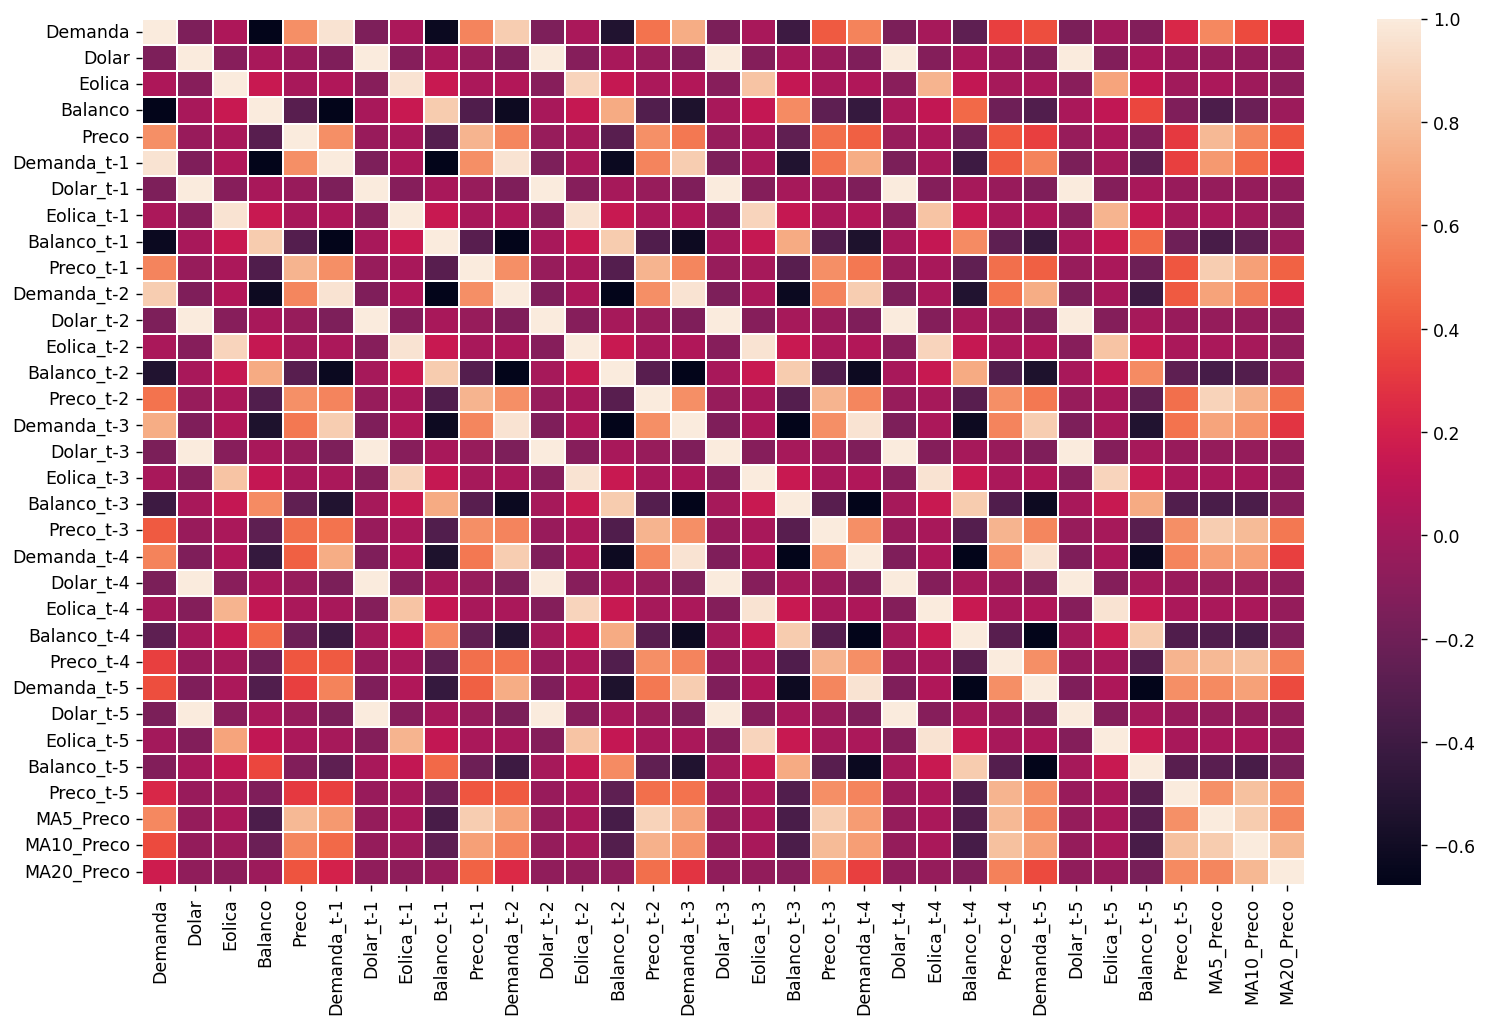

In [16]:
#Seleção de Features por Correlação de Pearson
corr_p = df_lag_ext.corr(method ='pearson')

#Plota do Mapa de Calor da Correlação de Pearson
plt.figure(figsize=(15,9), dpi = 125)
sns.heatmap(corr_p, annot=False, fmt=".1f", linewidth=.1)
plt.show()

In [17]:
#Define as colunas que serão variáveis de entrada - explicativas
features = df_lag_ext.columns[[9, 14, 19, 24, 29, 30, 31, 32]]

#Define a coluna que será variável de saída - interesse
target = df_lag_ext.columns[[4]]

#Separação de Dados para Ajuste e Validação dos Modelos
df_t_ajuste = df_lag_ext['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao = df_lag_ext['2009-08-01 00:00:00':].index.values
df_dados_ajuste = df_lag_ext['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao = df_lag_ext['2009-08-01 00:00:00':]

X_ajuste = df_dados_ajuste[features].values
Y_ajuste = df_dados_ajuste[target].values
X_validacao = df_dados_validacao[features].values
Y_validacao = df_dados_validacao[target].values

print(features)
print(target)

Index(['Preco_t-1', 'Preco_t-2', 'Preco_t-3', 'Preco_t-4', 'Preco_t-5',
       'MA5_Preco', 'MA10_Preco', 'MA20_Preco'],
      dtype='object')
Index(['Preco'], dtype='object')


In [27]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

modelo_MLP = Sequential()

neuron_camada_inter = 15
epocas = 10
funcao_ativacao_inter = 'relu'

#Camada de Entrada - Sempre deve especificar a quantidade de entrada
modelo_MLP.add(Input(shape=(features.size,)))
#modelo_MLP.add(Dense(features.size, input_dim=features.size, activation='relu'))

#Camada Intermediária - Deve especificar a quantidade de neurônios e a função de ativação
modelo_MLP.add(Dense(neuron_camada_inter, activation=funcao_ativacao_inter)) #2ª camada

#Camada de Saída - Deve especificar a quantidade de neurônios de saída
modelo_MLP.add(Dense(target.size))

#Configura Treinamento - loss é a métrica de avaliação // optimizer é o algoritmo de treinamento (adam; sgd; RMSprop)
modelo_MLP.compile(loss='mean_squared_error', optimizer='adam')

#epochs é a qtd. de épocas (iterações) de treinamento // #batch_size é a qtd. apresentada por iteração
modelo_MLP.fit(X_ajuste, Y_ajuste, epochs=epocas, batch_size=X_ajuste.shape[0], verbose=2)
#modelo_MLP.fit(X_ajuste, Y_ajuste, epochs=epocas, batch_size=X_ajuste.size, verbose=2)

df_previsto_MLP = modelo_MLP.predict(X_validacao)
df_previsto_MLP_denorm = df_previsto_MLP * df['Preco'].iloc[0]

Epoch 1/10
1/1 - 1s - 664ms/step - loss: 7.7145
Epoch 2/10
1/1 - 0s - 37ms/step - loss: 7.3890
Epoch 3/10
1/1 - 0s - 64ms/step - loss: 7.0719
Epoch 4/10
1/1 - 0s - 39ms/step - loss: 6.7633
Epoch 5/10
1/1 - 0s - 41ms/step - loss: 6.4634
Epoch 6/10
1/1 - 0s - 39ms/step - loss: 6.1720
Epoch 7/10
1/1 - 0s - 39ms/step - loss: 5.8895
Epoch 8/10
1/1 - 0s - 62ms/step - loss: 5.6159
Epoch 9/10
1/1 - 0s - 37ms/step - loss: 5.3511
Epoch 10/10
1/1 - 0s - 39ms/step - loss: 5.0952
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


In [28]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)

MAE = mean_absolute_error(y_true=Y_validacao, y_pred=df_previsto_MLP)
MSE = mean_squared_error(y_true=Y_validacao, y_pred=df_previsto_MLP)
R2 = r2_score(y_true=Y_validacao, y_pred=df_previsto_MLP)

print(f"Modelo - MAE: {round(MAE, 2)}")
print(f"Modelo - RMSE: {round((MSE**(1/2)), 2)}")
print(f"Modelo - R2: {round(R2, 2)}")

Modelo - MAE: 1.99
Modelo - RMSE: 2.26
Modelo - R2: -5.2


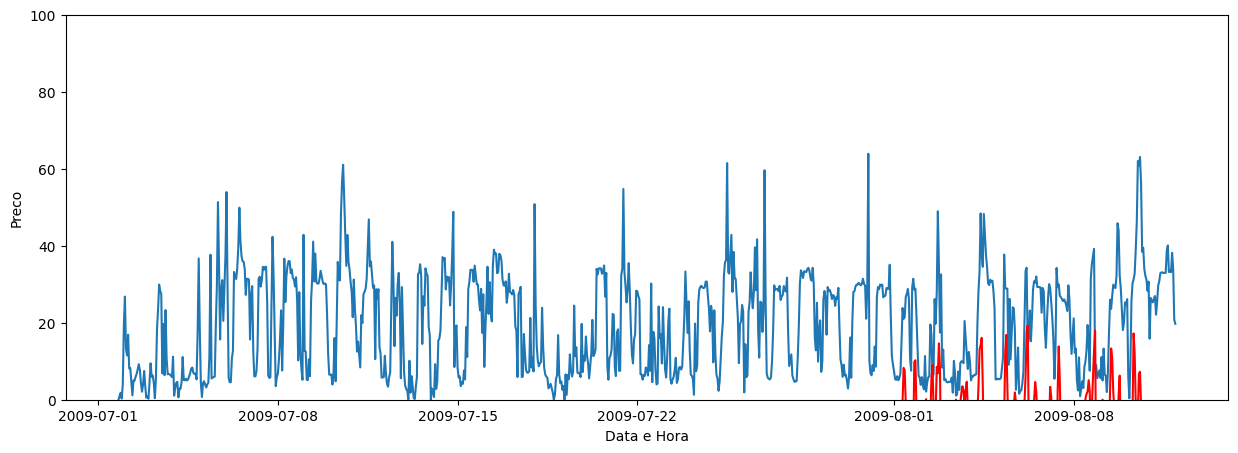

In [29]:
fig = plt.figure(figsize=(15,5))
plt.plot(df_lag_ext.index, df_lag_ext['Preco']*df['Preco'].iloc[0])
plt.plot(df_dados_validacao.index, df_previsto_MLP_denorm, 'r')
plt.ylabel('Preco')
plt.xlabel('Data e Hora')
plt.ylim(0,100)
plt.show()

#Caso queira salvar a figura, basta extrair o comentário da linha abaixo
#fig.savefig('resultado.png', format='png')